# DATA SCIENCE INTERN @OASIS INFOBYTE

## AUTHOR : SHREENIDHI MEDAR

# Task 3 : Car Price Prediction with Machine Learning

## 1. Import Necessary Libraries

In [1]:
# Core libraries for data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Notebook settings

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Clean chart style and default chart size
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14

# Show charts inside the notebook
%matplotlib inline

## 2. Load the Dataset

In [3]:
# Libraries for finding the file on disk
import os
import glob

# ---- Choose the data file ----
# Leave as None to auto-detect, or force a file: DATA_FILE = 'your_file.csv'
DATA_FILE = None

CANDIDATES = [
    'CAR DETAILS FROM CAR DEKHO.csv',
    'Car details v3.csv',
    'car details v3.csv',
]

if DATA_FILE is None:
    found = [f for f in CANDIDATES if os.path.exists(f)]
    if not found:
        # fall back to any CSV with "car" in its name
        found = sorted(f for f in glob.glob('*.csv') if 'car' in f.lower())
    if not found:
        raise FileNotFoundError(
            "Dataset not found. Download 'Vehicle dataset from cardekho' from Kaggle and place "
            "'CAR DETAILS FROM CAR DEKHO.csv' in the same folder as this notebook (or set DATA_FILE above)."
        )
    DATA_FILE = found[0]

print('Loading file:', DATA_FILE)
raw = pd.read_csv(DATA_FILE)
print('Raw shape  :', raw.shape)
raw.head()

Loading file: CAR DETAILS FROM CAR DEKHO.csv
Raw shape  : (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Data Inspection
A first look at the raw data: shape, column names, data types, null values and duplicates.

In [4]:
# Shape and column names
print('Shape (rows, columns):', raw.shape)
print('Columns:', list(raw.columns))

Shape (rows, columns): (4340, 8)
Columns: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [5]:
# Data types and non-null counts
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [6]:
# Null values and duplicate rows in the raw data
print('Missing values per column:')
print(raw.isnull().sum())
print('\nDuplicate rows:', int(raw.duplicated().sum()), f'({raw.duplicated().mean():.1%} of all rows)')

Missing values per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate rows: 763 (17.6% of all rows)


In [7]:
# Look at the categorical columns: spelling or capitalisation differences show up here
for col in raw.select_dtypes(include='object').columns:
    n = raw[col].nunique()
    if n <= 12:                                   # only show columns with few distinct values
        print(f'{col}: {sorted(raw[col].dropna().unique().tolist())}\n')

fuel: ['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol']

seller_type: ['Dealer', 'Individual', 'Trustmark Dealer']

transmission: ['Automatic', 'Manual']

owner: ['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']



## 4. Data Cleaning
Steps: tidy column names, handle null values, fix inconsistent categories ("Petrol" vs "petrol"), remove duplicates, and remove impossible values.

### 4.1 Tidy the column names

In [8]:
df = raw.copy()

# Lower-case, remove stray spaces, then use one standard name per column
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# 'car data.csv' has a 'Car_Name' column with only the model (e.g. "ritz"), so no brand can be extracted
if 'car_name' in df.columns:
    raise ValueError("This looks like 'car data.csv', which has no brand names. "
                     "Use 'CAR DETAILS FROM CAR DEKHO.csv' from the same Kaggle download instead.")
df = df.rename(columns={'car_name': 'name', 'kms_driven': 'km_driven', 'fuel_type': 'fuel'})

required = ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise KeyError(f'Columns not found: {missing_cols}. Columns present: {list(df.columns)}. '
                   "Use 'CAR DETAILS FROM CAR DEKHO.csv' (not 'car data.csv', which has no brand names).")

# Keep only the columns needed for this project
df = df[required]
print('Columns kept:', list(df.columns))

Columns kept: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


### 4.2 Handle null values

In [9]:
print('Rows before:', len(df))
print('Nulls per column:')
print(df.isnull().sum())

# Only a tiny share of rows have nulls, so dropping them is the simplest safe option
df = df.dropna()
print('\nRows after dropping nulls:', len(df))

Rows before: 4340
Nulls per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Rows after dropping nulls: 4340


### 4.3 Fix inconsistent categorical values
Spelling, capitalisation and extra spaces create fake categories ("Petrol", "petrol", " PETROL"). Every text value is stripped and converted to Title Case.

In [10]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']

print('BEFORE:')
for col in cat_cols:
    print(f'  {col}: {sorted(df[col].unique().tolist())}')

for col in cat_cols:
    df[col] = df[col].astype(str).str.strip().str.title()

print('\nAFTER:')
for col in cat_cols:
    print(f'  {col}: {sorted(df[col].unique().tolist())}')

BEFORE:
  fuel: ['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol']
  seller_type: ['Dealer', 'Individual', 'Trustmark Dealer']
  transmission: ['Automatic', 'Manual']
  owner: ['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']

AFTER:
  fuel: ['Cng', 'Diesel', 'Electric', 'Lpg', 'Petrol']
  seller_type: ['Dealer', 'Individual', 'Trustmark Dealer']
  transmission: ['Automatic', 'Manual']
  owner: ['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']


### 4.4 Remove duplicates

In [11]:
before = len(df)
df = df.drop_duplicates()
print(f'Duplicate rows removed: {before - len(df)}  (rows left: {len(df)})')

Duplicate rows removed: 763  (rows left: 3577)


### 4.5 Fix data types and remove impossible values

In [12]:
# Make sure the numeric columns are numeric
for col in ['year', 'selling_price', 'km_driven']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna()

# The Kaggle file stores the price in rupees. Convert to lakh rupees (1 lakh = 100,000) for easier reading.
if df['selling_price'].median() > 10_000:
    df['selling_price'] = df['selling_price'] / 100_000
print('Selling price is now in lakh rupees.')

# Remove rows that cannot be real
from datetime import datetime
CURRENT_YEAR = datetime.now().year

n_before = len(df)
bad_price = df['selling_price'] <= 0
bad_km = (df['km_driven'] < 0) | (df['km_driven'] > 500_000)        # over 5 lakh km is almost certainly a typing error
bad_year = (df['year'] < 1980) | (df['year'] > CURRENT_YEAR)
print(f'Non-positive prices: {bad_price.sum()} | unrealistic km_driven: {bad_km.sum()} | impossible year: {bad_year.sum()}')

df = df[~(bad_price | bad_km | bad_year)].reset_index(drop=True)
df['year'] = df['year'].astype(int)
print(f'Rows removed: {n_before - len(df)}  |  Clean dataset shape: {df.shape}')

Selling price is now in lakh rupees.
Non-positive prices: 0 | unrealistic km_driven: 2 | impossible year: 0
Rows removed: 2  |  Clean dataset shape: (3575, 8)


In [13]:
# Descriptive statistics of the numeric columns after cleaning
df[['year', 'selling_price', 'km_driven']].describe().round(2)

,year,selling_price,km_driven
count,3575.00,3575.00,3575.00
mean,2012.96,4.74,68907.02
std,4.25,5.09,45227.12
min,1992.00,0.20,1.00
25%,2010.00,2.00,36000.00
50%,2013.00,3.50,60000.00
75%,2016.00,6.00,90000.00
max,2020.00,89.00,400000.00


## 5. Feature Engineering
Two new features are created:
- **car_age** = current year minus the manufacturing year (a car's age matters more than its raw year).
- **brand** = the first word of the car name (e.g. "Maruti Swift VDI" becomes "Maruti").

In [14]:
# 1) Car age from the year column
df['car_age'] = CURRENT_YEAR - df['year']

# 2) Brand from the car name: take the first word
df['brand'] = df['name'].str.strip().str.split().str[0].str.title()

# Some brands have two words, and some abbreviations lose their capitals with .title(): fix them
BRAND_FIX = {'Land': 'Land Rover', 'Force': 'Force Motors', 'Ashok': 'Ashok Leyland',
             'Bmw': 'BMW', 'Mg': 'MG'}
df['brand'] = df['brand'].replace(BRAND_FIX)

print('Brands found:', df['brand'].nunique())
df[['name', 'brand', 'year', 'car_age']].head()

Brands found: 29


,name,brand,year,car_age
0,Maruti 800 AC,Maruti,2007,19
1,Maruti Wagon R LXI Minor,Maruti,2007,19
2,Hyundai Verna 1.6 SX,Hyundai,2012,14
3,Datsun RediGO T Option,Datsun,2017,9
4,Honda Amaze VX i-DTEC,Honda,2014,12


In [15]:
# Brands with very few cars give the model almost nothing to learn from. Group them as "Other".
MIN_CARS_PER_BRAND = 15
brand_counts = df['brand'].value_counts()
rare = brand_counts[brand_counts < MIN_CARS_PER_BRAND].index
df['brand'] = df['brand'].where(~df['brand'].isin(rare), 'Other')

print(f'Brands grouped into "Other": {len(rare)}  |  Brands now: {df["brand"].nunique()}')
df['brand'].value_counts()

Brands grouped into "Other": 12  |  Brands now: 18


Maruti           1070
Hyundai           637
Mahindra          328
Tata              308
Ford              220
Honda             216
Toyota            170
Chevrolet         151
Renault           110
Volkswagen         93
Nissan             52
Skoda              49
Other              33
Fiat               32
Audi               31
Datsun             29
BMW                25
Mercedes-Benz      21
Name: brand, dtype: int64

## 6. Exploratory Data Analysis (EDA)

### 6.1 Distribution of selling prices

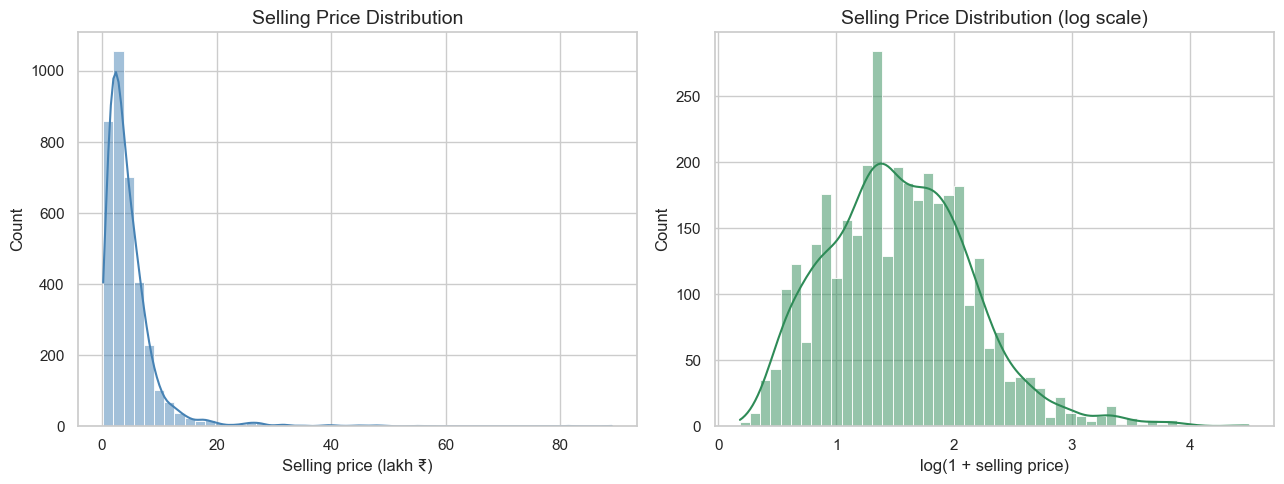

Mean price  : 4.74 lakh
Median price: 3.50 lakh
Skewness    : 5.45  (0 = symmetric; above 1 = strongly right-skewed)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df['selling_price'], bins=50, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Selling Price Distribution')
axes[0].set_xlabel('Selling price (lakh ₹)')

sns.histplot(np.log1p(df['selling_price']), bins=50, kde=True, color='seagreen', ax=axes[1])
axes[1].set_title('Selling Price Distribution (log scale)')
axes[1].set_xlabel('log(1 + selling price)')

plt.tight_layout()
plt.show()

print(f"Mean price  : {df['selling_price'].mean():.2f} lakh")
print(f"Median price: {df['selling_price'].median():.2f} lakh")
print(f"Skewness    : {df['selling_price'].skew():.2f}  (0 = symmetric; above 1 = strongly right-skewed)")

**Observation:** prices are strongly **right-skewed**: most used cars are cheap and a few luxury cars are very expensive, so the mean is well above the median. On a log scale the shape is much closer to a bell curve. This is why the models in this notebook learn the **log of the price** (explained in Section 11), and why a few luxury cars will always be the hardest to predict.

### 6.2 Price vs fuel type (box plots)

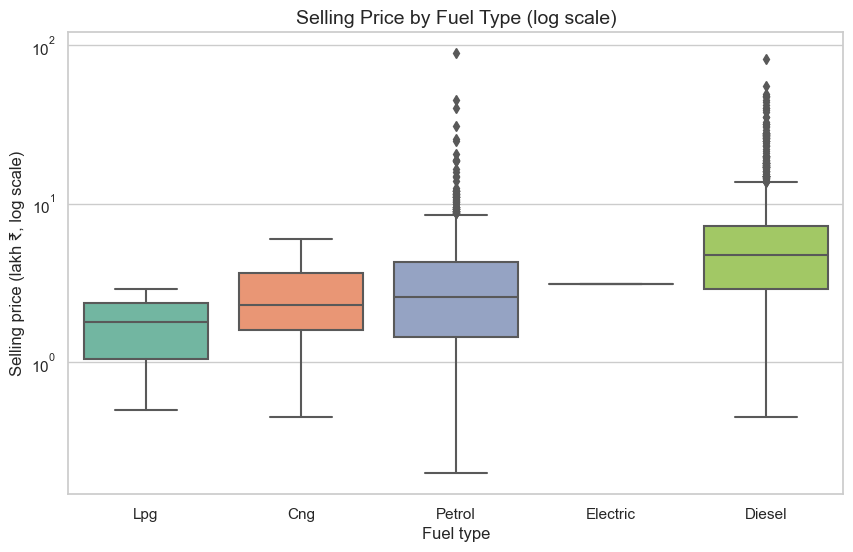

,count,median,mean
fuel,,,
Lpg,22,1.80,1.72
Cng,37,2.30,2.73
Petrol,1716,2.60,3.35
Electric,1,3.10,3.10
Diesel,1799,4.75,6.14


In [17]:
order = df.groupby('fuel')['selling_price'].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='fuel', y='selling_price', order=order, palette='Set2', ax=ax)
ax.set_yscale('log')                          # log axis so cheap and expensive cars are both readable
ax.set_title('Selling Price by Fuel Type (log scale)')
ax.set_xlabel('Fuel type')
ax.set_ylabel('Selling price (lakh ₹, log scale)')
plt.show()

display(df.groupby('fuel')['selling_price'].agg(['count', 'median', 'mean']).round(2).sort_values('median'))

**Observation:** the y-axis is logarithmic, so equal vertical steps mean equal *percentage* changes. Diesel cars usually sit higher than petrol cars. Fuel types with only a handful of cars (check the `count` column) have unreliable boxes, so do not read too much into them. Fuel type also overlaps with other things: diesel cars tend to be bigger and newer, so part of the "diesel premium" is really a size and age effect.

### 6.3 Price vs car age (scatter plot)

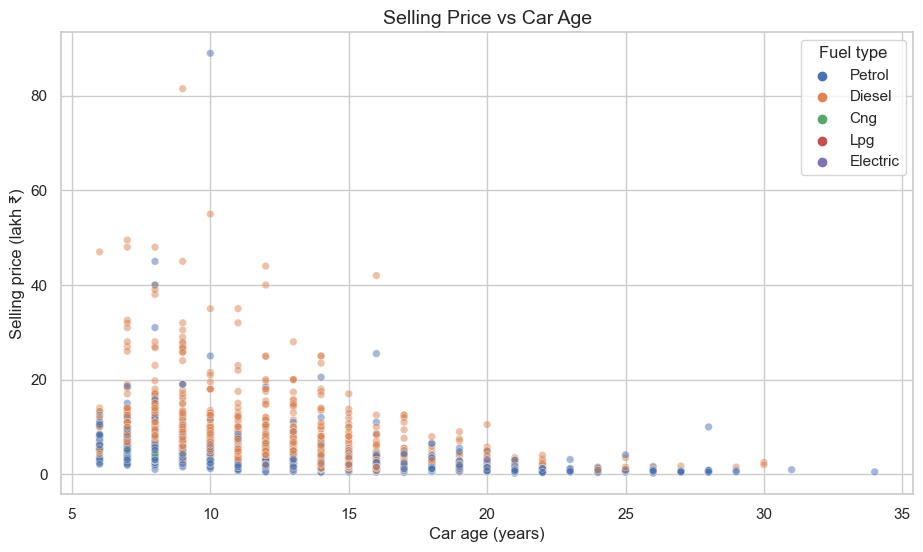

Correlation between car age and price: -0.42


In [18]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=df, x='car_age', y='selling_price', hue='fuel', alpha=0.5, s=30, ax=ax)
ax.set_title('Selling Price vs Car Age')
ax.set_xlabel('Car age (years)')
ax.set_ylabel('Selling price (lakh ₹)')
ax.legend(title='Fuel type')
plt.show()

print(f"Correlation between car age and price: {df['car_age'].corr(df['selling_price']):.2f}")

**Observation:** price falls as cars get older (negative correlation), but the relationship is a *curve*, not a straight line: the biggest drop happens in the first few years. At every age there is a wide spread of prices, because brand and model matter a lot. That spread is the reason age alone cannot predict price well.

### 6.4 More views: price by brand and price vs kilometres driven

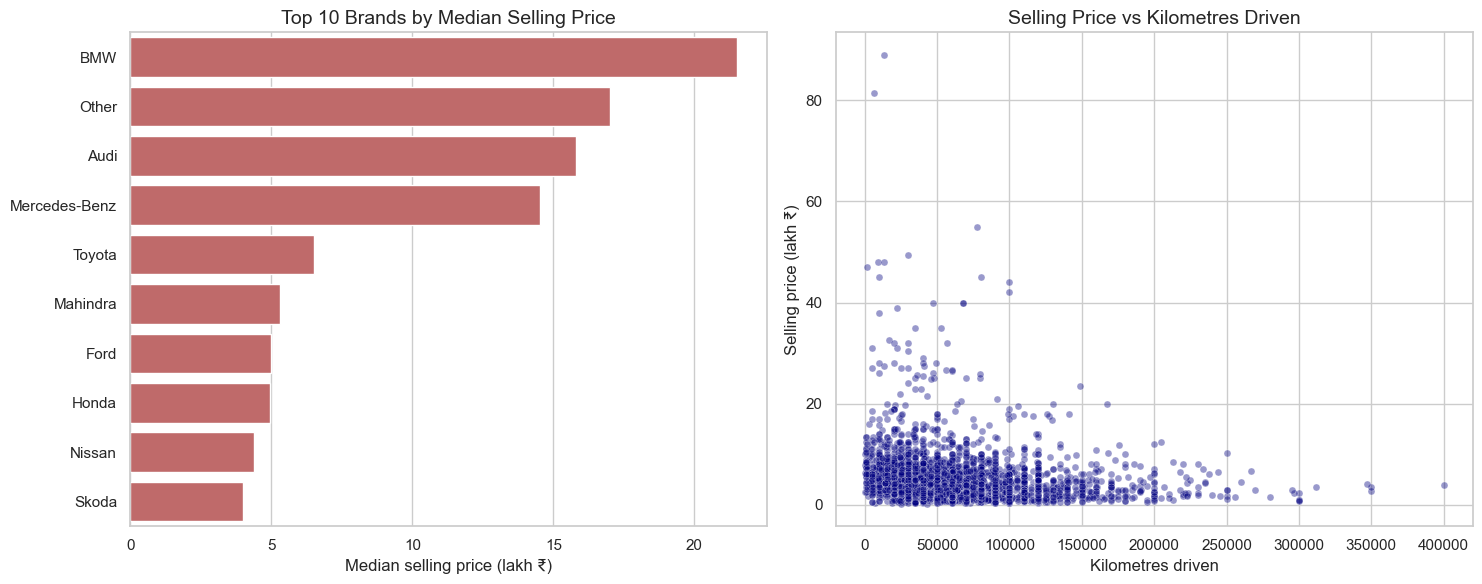

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Median price of the 10 most expensive brands
top_brands = df.groupby('brand')['selling_price'].median().sort_values(ascending=False).head(10)
sns.barplot(x=top_brands.values, y=top_brands.index, color='indianred', ax=axes[0])
axes[0].set_title('Top 10 Brands by Median Selling Price')
axes[0].set_xlabel('Median selling price (lakh ₹)')
axes[0].set_ylabel('')

# Price vs kilometres driven
sns.scatterplot(data=df, x='km_driven', y='selling_price', alpha=0.4, s=25, color='navy', ax=axes[1])
axes[1].set_title('Selling Price vs Kilometres Driven')
axes[1].set_xlabel('Kilometres driven')
axes[1].set_ylabel('Selling price (lakh ₹)')

plt.tight_layout()
plt.show()

**Observation:** brand is a strong price signal: luxury brands have median prices several times higher than mass-market brands. Price falls with kilometres driven, but the pattern is noisy because high-mileage cars are also usually older.

## 7. Encode Categorical Variables
Models need numbers, so text columns are converted:

In [20]:
# Ordinal encoding for owner (number of previous owners)
OWNER_MAP = {'First Owner': 1, 'Second Owner': 2, 'Third Owner': 3,
             'Fourth & Above Owner': 4, 'Test Drive Car': 0}
df['owner_num'] = df['owner'].map(OWNER_MAP)

unmapped = df['owner_num'].isnull().sum()
print('Owner values not in the mapping:', unmapped)
df['owner_num'] = df['owner_num'].fillna(df['owner_num'].median())     # safe fallback if a new label appears

# Keep only the columns the model will use
model_df = df[['selling_price', 'car_age', 'km_driven', 'owner_num',
               'fuel', 'seller_type', 'transmission', 'brand']]

# One-hot encoding for the unordered categories
encoded = pd.get_dummies(model_df, columns=['fuel', 'seller_type', 'transmission', 'brand'],
                         drop_first=True, dtype=int)

print('Encoded shape:', encoded.shape)
encoded.head()

Owner values not in the mapping: 0
Encoded shape: (3575, 28)


,selling_price,car_age,km_driven,owner_num,fuel_Diesel,fuel_Electric,fuel_Lpg,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,...,brand_Mahindra,brand_Maruti,brand_Mercedes-Benz,brand_Nissan,brand_Other,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen
0,0.60,19,70000,1,0,0,0,1,1,0,...,0,1,0,0,0,0,0,0,0,0
1,1.35,19,50000,1,0,0,0,1,1,0,...,0,1,0,0,0,0,0,0,0,0
2,6.00,14,100000,1,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,2.50,9,46000,1,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,4.50,12,141000,2,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


## 8. Feature Correlation Heatmap
Brand columns are left out of the heatmap because there are too many of them to read. They are included in the model itself.

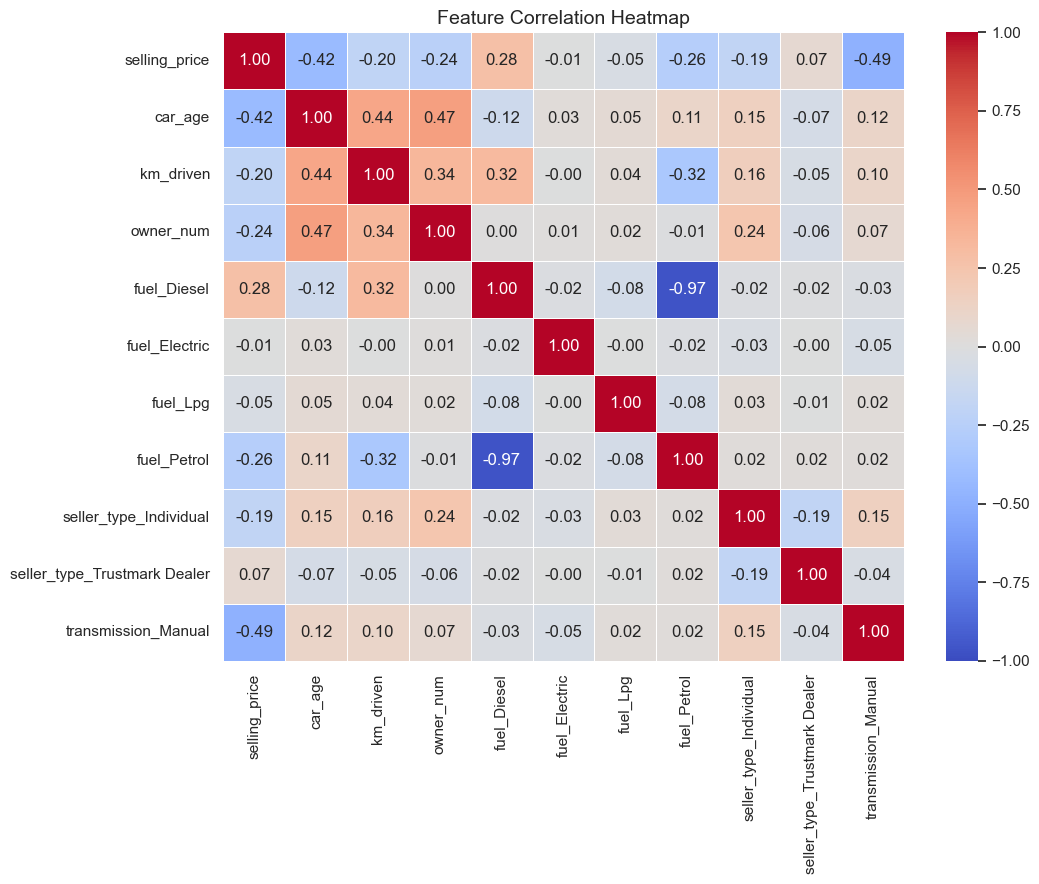

Top 8 features by correlation with price:
transmission_Manual   -0.49
car_age               -0.42
brand_BMW              0.29
fuel_Diesel            0.28
brand_Mercedes-Benz    0.28
fuel_Petrol           -0.26
owner_num             -0.24
brand_Other            0.23


In [21]:
non_brand = [c for c in encoded.columns if not c.startswith('brand_')]

plt.figure(figsize=(11, 9))
sns.heatmap(encoded[non_brand].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.4)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

# Strongest relationships with price (all features, including brands)
corr_price = encoded.corr()['selling_price'].drop('selling_price')
print('Top 8 features by correlation with price:')
print(corr_price.reindex(corr_price.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

## 9. Train/Test Split
80% of the data is used to train the models and 20% is kept hidden to test them. `random_state` makes the split repeatable.

In [22]:
# Library for splitting the data
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = encoded.drop(columns='selling_price')      # features
y = encoded['selling_price']                   # target: selling price in lakh ₹

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print('Training set:', X_train.shape)
print('Test set    :', X_test.shape)
print('Number of features:', X.shape[1])

Training set: (2860, 27)
Test set    : (715, 27)
Number of features: 27


## 10. Import Machine Learning Libraries
Data preparation is finished, so the machine learning libraries are imported now.

In [23]:
# Scaling, pipeline and target-transform tools
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor

# The three regression models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

## 11. Train the Regression Models

Three models are trained
1. **Linear Regression**
2. **Random Forest Regressor**
3. **Gradient Boosting Regressor**

In [24]:
def with_log_target(model):
    """Train on log(1 + price), but predict in the original price units."""
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)


models = {
    'Linear Regression': with_log_target(make_pipeline(StandardScaler(), LinearRegression())),
    'Random Forest': with_log_target(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    'Gradient Boosting': with_log_target(GradientBoostingRegressor(n_estimators=300, learning_rate=0.1,
                                                                    max_depth=3, random_state=RANDOM_STATE)),
}

# Fit every model on the training data
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'Trained: {name}')

Trained: Linear Regression
Trained: Random Forest
Trained: Gradient Boosting


## 12. Evaluate the Models (MAE, RMSE, R²)

### 12.1 Import the evaluation metrics

In [25]:
# Metrics used to judge the models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 12.2 Score every model on the test set
- **MAE** (Mean Absolute Error)
- **RMSE** (Root Mean Squared Error)
- **R²**

In [26]:
rows = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        'Model': name,
        'MAE (lakh ₹)': mean_absolute_error(y_test, pred),
        'RMSE (lakh ₹)': np.sqrt(mean_squared_error(y_test, pred)),
        'R² (test)': r2_score(y_test, pred),
        'R² (train)': r2_score(y_train, model.predict(X_train)),
    })

results = pd.DataFrame(rows).set_index('Model').round(3)
results.sort_values('R² (test)', ascending=False)

,MAE (lakh ₹),RMSE (lakh ₹),R² (test),R² (train)
Model,,,,
Linear Regression,1.523,3.350,0.647,0.694
Random Forest,1.578,3.569,0.600,0.908
Gradient Boosting,1.529,3.598,0.593,0.759


In [27]:
print(f"Average selling price in the test set: {y_test.mean():.2f} lakh ₹")
print(f"Median selling price in the test set : {y_test.median():.2f} lakh ₹")
print('\nFor scale: an MAE of 1.0 means the average prediction is off by about ₹1,00,000.')

Average selling price in the test set: 4.87 lakh ₹
Median selling price in the test set : 3.50 lakh ₹

For scale: an MAE of 1.0 means the average prediction is off by about ₹1,00,000.


### 12.3 Actual vs predicted prices
Points close to the red diagonal line are accurate predictions.

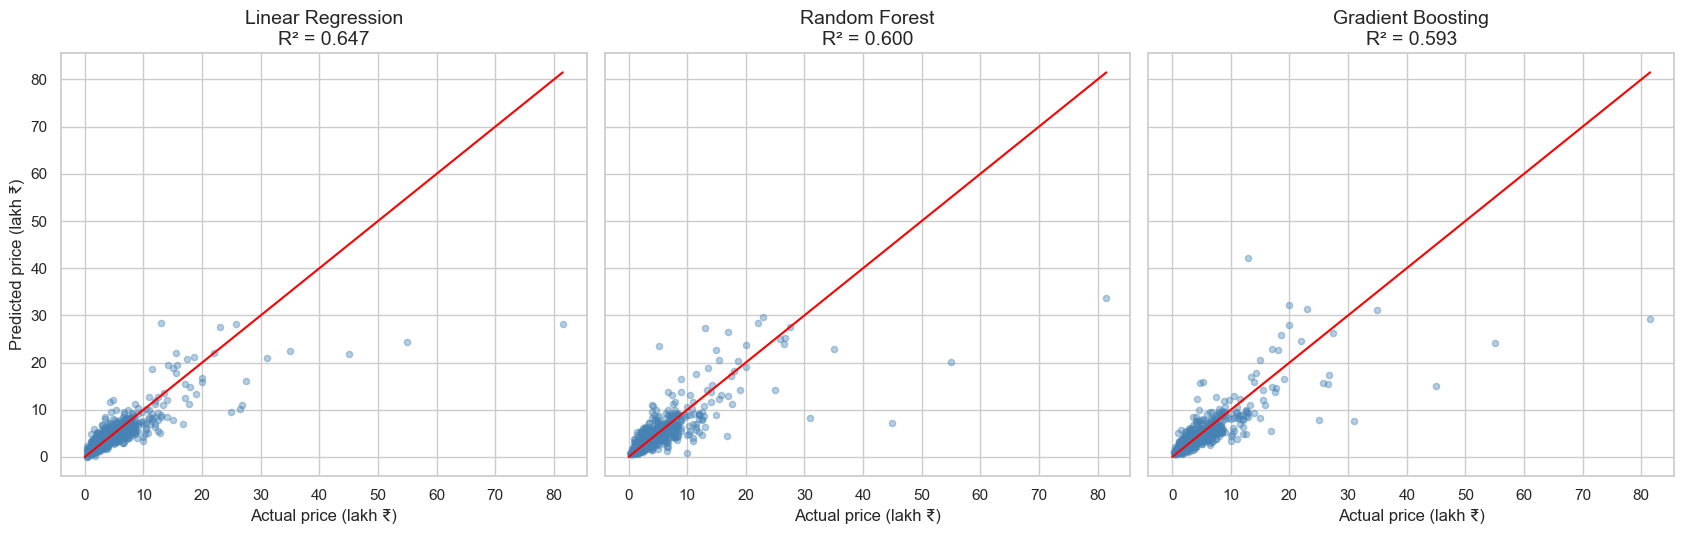

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharex=True, sharey=True)
limit = max(y_test.max(), max(p.max() for p in predictions.values()))

for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.4, s=20, color='steelblue')
    ax.plot([0, limit], [0, limit], color='red', lw=1.5)          # perfect-prediction line
    ax.set_title(f"{name}\nR² = {results.loc[name, 'R² (test)']:.3f}")
    ax.set_xlabel('Actual price (lakh ₹)')
axes[0].set_ylabel('Predicted price (lakh ₹)')
plt.tight_layout()
plt.show()

**Observation:** points hugging the red line are accurate. Predictions for cheap cars (bottom-left) are usually tight, while the expensive cars (top-right) are scattered further from the line. That is expected: there are few luxury cars to learn from, and the same name can cover very different variants and conditions that the dataset does not record.

## 13. Cross-Validation
A single 80/20 split can be lucky or unlucky. **5-fold cross-validation** trains and tests each model 5 times on different splits of all the data, which gives a more reliable score.

In [29]:
# Cross-validation tools
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='r2')
    cv_rows.append({'Model': name, 'CV mean R²': scores.mean(), 'CV std': scores.std()})
    print(f'{name}: mean R² = {scores.mean():.3f} (+/- {scores.std():.3f})')

cv_results = pd.DataFrame(cv_rows).set_index('Model').round(3)

Linear Regression: mean R² = 0.683 (+/- 0.047)
Random Forest: mean R² = 0.638 (+/- 0.065)
Gradient Boosting: mean R² = 0.647 (+/- 0.116)


## 14. Best Model and Feature Importance

### 14.1 Declare the best model

In [30]:
summary = results.join(cv_results)
summary = summary.sort_values(['CV mean R²', 'R² (test)'], ascending=False)
display(summary)

best_name = summary.index[0]
print(f'\nBEST MODEL: {best_name}')
print(f"  Test R²      : {summary.loc[best_name, 'R² (test)']:.3f}")
print(f"  CV mean R²   : {summary.loc[best_name, 'CV mean R²']:.3f}")
print(f"  Test MAE     : {summary.loc[best_name, 'MAE (lakh ₹)']:.2f} lakh ₹")
print(f"  Test RMSE    : {summary.loc[best_name, 'RMSE (lakh ₹)']:.2f} lakh ₹")

gap = summary['CV mean R²'].max() - summary['CV mean R²'].min()
print(f'\nSpread between best and worst model (CV R²): {gap:.3f}')

,MAE (lakh ₹),RMSE (lakh ₹),R² (test),R² (train),CV mean R²,CV std
Model,,,,,,
Linear Regression,1.523,3.350,0.647,0.694,0.683,0.047
Gradient Boosting,1.529,3.598,0.593,0.759,0.647,0.116
Random Forest,1.578,3.569,0.600,0.908,0.638,0.065



BEST MODEL: Linear Regression
  Test R²      : 0.647
  CV mean R²   : 0.683
  Test MAE     : 1.52 lakh ₹
  Test RMSE    : 3.35 lakh ₹

Spread between best and worst model (CV R²): 0.045


### 14.2 Feature importance chart (best model)

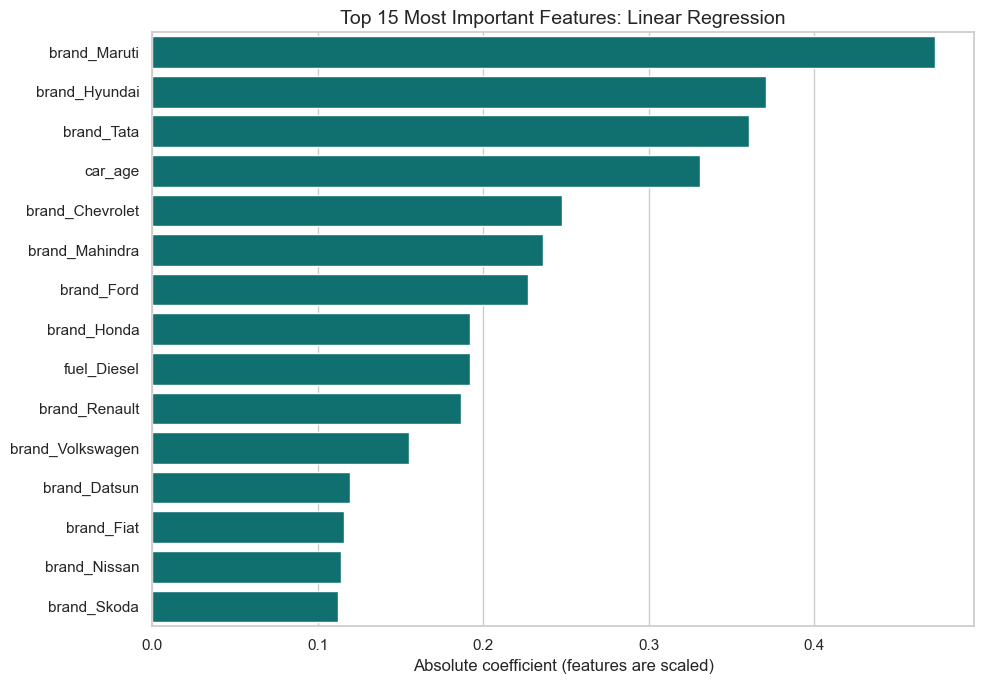

brand_Maruti       0.4731
brand_Hyundai      0.3710
brand_Tata         0.3608
car_age            0.3313
brand_Chevrolet    0.2475
brand_Mahindra     0.2365
brand_Ford         0.2268
brand_Honda        0.1918


In [31]:
# Get the fitted model inside the log-target wrapper
inner = models[best_name].regressor_
if hasattr(inner, 'named_steps'):              # a pipeline: take its last step (the actual model)
    inner = inner.steps[-1][1]

if hasattr(inner, 'feature_importances_'):     # tree-based models
    importance = pd.Series(inner.feature_importances_, index=X.columns)
    xlabel = 'Importance (share of total, sums to 1)'
else:                                          # linear model: size of the coefficient (features were scaled)
    importance = pd.Series(np.abs(inner.coef_), index=X.columns)
    xlabel = 'Absolute coefficient (features are scaled)'

top_n = 15
top_features = importance.sort_values(ascending=False).head(top_n)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=top_features.values, y=top_features.index, color='teal', ax=ax)
ax.set_title(f'Top {top_n} Most Important Features: {best_name}')
ax.set_xlabel(xlabel)
ax.set_ylabel('')
plt.tight_layout()
plt.show()

print(top_features.round(4).head(8).to_string())

## 15. Predict the Price of a New Car

In [32]:
def predict_price(name, year, km_driven, fuel, seller_type, transmission, owner='First Owner'):
    """Predict a used car's selling price (lakh ₹) with the best model."""
    brand = name.strip().split()[0].title()
    brand = BRAND_FIX.get(brand, brand)
    if brand in rare:                                   # brands grouped as "Other" during training
        brand = 'Other'

    row = pd.DataFrame([{
        'car_age': CURRENT_YEAR - year,
        'km_driven': km_driven,
        'owner_num': OWNER_MAP.get(owner.title(), 1),
        'fuel': fuel.title(), 'seller_type': seller_type.title(),
        'transmission': transmission.title(), 'brand': brand,
    }])
    row = pd.get_dummies(row, columns=['fuel', 'seller_type', 'transmission', 'brand'], dtype=int)
    row = row.reindex(columns=X.columns, fill_value=0)   # same columns, same order as training
    return float(models[best_name].predict(row)[0])


example_brand = df['brand'].value_counts().index[0]     # the most common brand in the data
price = predict_price(f'{example_brand} Example Model', 2016, 60000, 'Petrol', 'Individual', 'Manual')
print(f'Predicted price of a 2016 {example_brand}, 60,000 km, petrol, manual, first owner: {price:.2f} lakh ₹')

Predicted price of a 2016 Maruti, 60,000 km, petrol, manual, first owner: 3.59 lakh ₹


# THANK YOU